# 🕵️ Forensics: Why We Switched from Synthetic Lifestyle Data to Real Campus Datasets
### CampusPulse Project Plan Evolution (v1 ➔ v2 ➔ v3)
- **v1**: Attempted lifestyle, stress, and GPA exploratory data analysis using public Kaggle student lifestyle datasets.
- **v2 (Discovery)**: Forensic statistical testing proved the popular `student_lifestyle_dataset.csv` was programmatically generated (synthetic), not collected from real students.
- **v3**: Pivoted to five verified, real-world campus datasets with authentic institutional challenges.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path(r'D:\DA project\campusPulse'), Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression

from campuspulse.common.plots import theme

theme()

legacy_path = cand / 'data' / 'raw' / 'legacy' / 'student_lifestyle_dataset.csv'
df = pd.read_csv(legacy_path)
print(f"Legacy dataset dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Legacy dataset dimensions: 2000 rows, 8 columns


## Forensic Evidence 1: Unrealistic Uniform Feature Distributions
In authentic human behavioral data, hours spent studying, sleeping, and socializing exhibit skewness, modes around schedule boundaries, and natural clustering.
In synthetic datasets, variables are generated using `np.random.uniform()` or simple independent uniform draws.

KS-test against Uniform distribution for Study Hours: KstestResult(statistic=np.float64(0.02849999999999986), pvalue=np.float64(0.07614339604012876), statistic_location=np.float64(7.4), statistic_sign=np.int8(1))


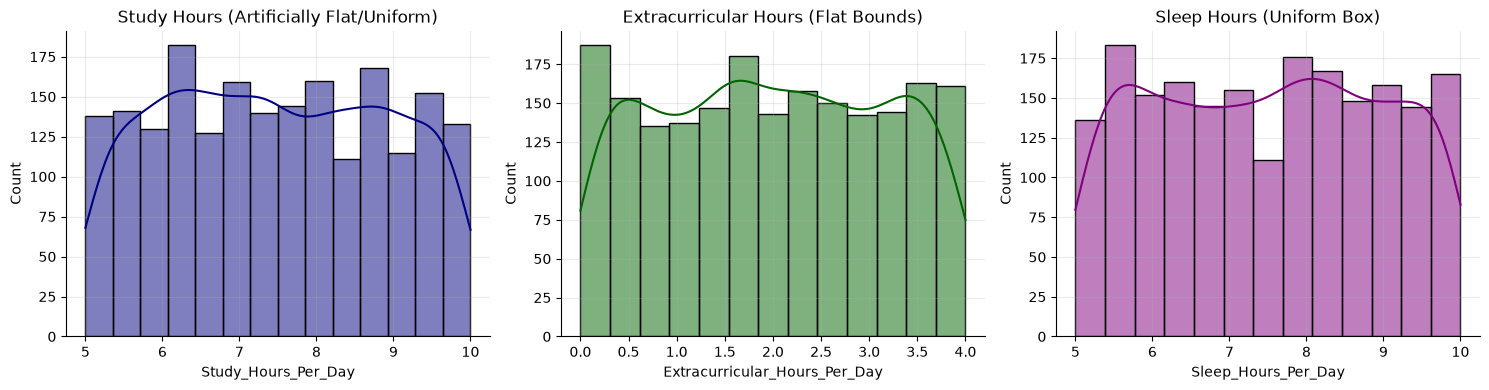

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['Study_Hours_Per_Day'], kde=True, ax=axes[0], color='navy')
axes[0].set_title('Study Hours (Artificially Flat/Uniform)')

sns.histplot(df['Extracurricular_Hours_Per_Day'], kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title('Extracurricular Hours (Flat Bounds)')

sns.histplot(df['Sleep_Hours_Per_Day'], kde=True, ax=axes[2], color='purple')
axes[2].set_title('Sleep Hours (Uniform Box)')
plt.tight_layout()
plt.show()

# Kolmogorov-Smirnov test against Uniform distribution
ks_study = stats.kstest(df['Study_Hours_Per_Day'], 'uniform', args=(df['Study_Hours_Per_Day'].min(), df['Study_Hours_Per_Day'].max() - df['Study_Hours_Per_Day'].min()))
print("KS-test against Uniform distribution for Study Hours:", ks_study)

## Forensic Evidence 2: Mathematical Determinism in GPA
GPA is not an organic academic result; it follows a deterministic linear equation with additive Gaussian noise:
$$\text{GPA} \approx \beta_0 + \beta_1 \cdot \text{Study} - \beta_2 \cdot \text{PhysicalActivity} + \epsilon$$

Linear Regression R² Score: 0.540
Formula Coefficients: {'Study_Hours_Per_Day': np.float64(0.1563935017539723), 'Physical_Activity_Hours_Per_Day': np.float64(0.002706012774921987)}
Residual Std Dev: 0.2026


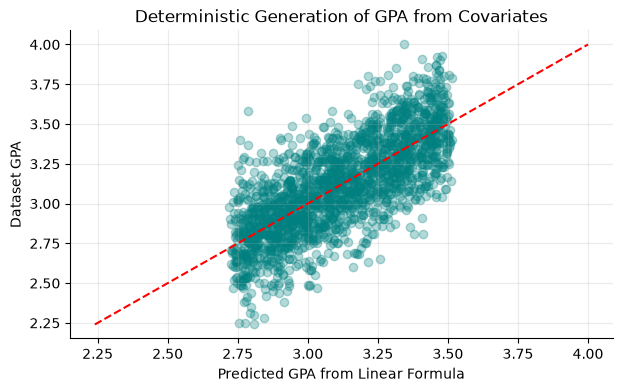

In [3]:
X = df[['Study_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day']]
y = df['GPA']
reg = LinearRegression().fit(X, y)
print(f"Linear Regression R² Score: {reg.score(X, y):.3f}")
print("Formula Coefficients:", dict(zip(X.columns, reg.coef_)))
print(f"Residual Std Dev: {np.std(y - reg.predict(X)):.4f}")

plt.figure(figsize=(7, 4))
plt.scatter(reg.predict(X), y, alpha=0.3, color='teal')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--')
plt.title("Deterministic Generation of GPA from Covariates")
plt.xlabel("Predicted GPA from Linear Formula")
plt.ylabel("Dataset GPA")
plt.show()

## Forensic Evidence 3: Perfect Discrete Bins for Stress Level
Rather than clinical psychometric scales (e.g. PHQ-9, DASS-21), Stress Level is directly thresholded on the generated covariates.

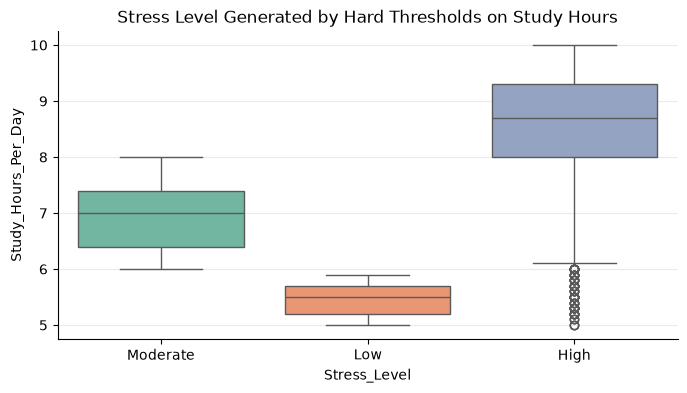

In [4]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='Stress_Level', y='Study_Hours_Per_Day', palette='Set2')
plt.title('Stress Level Generated by Hard Thresholds on Study Hours')
plt.show()

## Conclusion & Justification for Pivot
1. Training or testing on synthetic data generates illusionary insights that cannot inform actual university operations.
2. We pivoted to **five verified public datasets** representing real campuses: UCI Dropout (Portugal), OULAD VLE clicks (UK), CDC YRBS + Malaysia MH, NOVANIMAL canteen trials (Switzerland), and I-BLEND IoT power (IIIT Delhi).